# Compression 04 — Codage entropique ANS (rANS et tANS)

> Sous-série `Compression` · Carnet 4 · Pli 5 de l'[EPIC #18706](https://github.com/jsboige/CoursIA/issues/18706)

Le carnet 03 a chassé la **redondance entre symboles** (LZ77 : la deuxième
occurrence ne se code pas, elle se référence). Nous revenons ici à la
**redondance statistique** d'un alphabet, celle des carnets 01 et 02 — mais
pour en briser le plafond. Huffman est optimal *parmi les codes préfixes à
longueurs entières* : sur une source très déséquilibrée, cette restriction
coûte jusqu'à un bit entier par symbole. Les **Asymmetric Numeral Systems**
(ANS) de Jarosław Duda lèvent cette restriction en partageant les bits
fractionnaires entre symboles, au prix d'un unique état arithmétique.

**Prérequis** : entropie de Shannon, codes préfixes, Huffman canonique
(carnets 01-02), LZ77 (carnet 03).

**Plan** :

1. Le plafond Huffman : un demi-bit de trop en moyenne, un bit entier dans le pire cas
2. rANS : coder un symbole, c'est multiplier un entier
3. rANS en blocs : borner l'état pour streamer
4. tANS : congeler rANS dans des tables de $2^L$ états
5. Banc comparatif : taux et débits contre Huffman et zlib
6. Exercices

Comme dans toute la série, le banc mesure sur une tranche réelle du
*Horla* de Maupassant (1887), le corpus de référence du dépôt.

In [1]:
import hashlib
import math
import random
import time
from heapq import heapify, heappop, heappush
from pathlib import Path

import matplotlib.pyplot as plt
import zlib

## 1. Le plafond Huffman

Un code préfixe donne à chaque symbole un mot de **longueur entière**. Le code
optimal assignerait au symbole de probabilité $p$ la longueur « idéale »
$-\log_2 p$, qui est fractionnaire dès que $p$ n'est pas une puissance de
$1/2$. Huffman arrondit au mieux : sa longueur moyenne vérifie

$$H \;\le\; \bar{\ell}_{\text{Huff}} \;<\; H + 1 \quad \text{bits/symbole}.$$

Sur un alphabet raisonnablement plat (le français en octets), l'écart ne
dépasse pas quelques centièmes de bit. Mais sur une source **déséquilibrée**
— un symbole à 99 % — le symbole dominant mériterait 0,0145 bit et Huffman
lui en donne **au moins un entier** : l'écart tend vers le bit entier.
C'est ce plafond qu'ANS abat : les bits fractionnaires sont portés par un
état partagé entre tous les symboles, pas par des mots isolés.

In [2]:
chemin = Path("../GenAI/Audio/04-Applications/datasets/le_horla_1887.txt")
octets = chemin.read_bytes()[:131072]
tranche = octets[:16384]
n = len(tranche)
freqs = {}
for b in tranche:
    freqs[b] = freqs.get(b, 0) + 1
H = -sum((c / n) * math.log2(c / n) for c in freqs.values())

print(f"corpus : {chemin.name} ({chemin.stat().st_size} octets)")
print(f"empreinte SHA-256 (extrait de 128 Kio) : {hashlib.sha256(octets).hexdigest()[:24]}...")
print(f"tranche d'etude : {n} octets, {len(freqs)} symboles distincts")
print(f"entropie H = {H:.4f} bits/octet")

corpus : le_horla_1887.txt (256791 octets)
empreinte SHA-256 (extrait de 128 Kio) : 7f8ef93995d36dff489f0d7e...
tranche d'etude : 16384 octets, 81 symboles distincts
entropie H = 4.6198 bits/octet


### Lecture du résultat

Le français en octets est un alphabet **plat** : 81 symboles distincts sur
16 Kio, une entropie de l'ordre de 4,62 bits/octet (le maximum serait
$log_2 81 \approx 6,34$). C'est le régime où Huffman est presque
parfait — nous verrons en section 5 que son écart à l'entropie se compte
en centièmes de bit. Le cas déséquilibré, construit juste après, montre
l'autre régime.

In [3]:
def huffman_longueurs(frequences):
    """Longueurs de code Huffman par fusion reiteree des deux minima (tas)."""
    tas = [(fq, i, [s]) for i, (s, fq) in enumerate(sorted(frequences.items()))]
    heapify(tas)
    longueurs = {s: 0 for s in frequences}
    compteur = len(tas)
    while len(tas) > 1:
        f1, _, s1 = heappop(tas)
        f2, _, s2 = heappop(tas)
        for s in s1 + s2:
            longueurs[s] += 1
        compteur += 1
        heappush(tas, (f1 + f2, compteur, s1 + s2))
    return longueurs


def codes_canoniques(longueurs):
    """Codes canoniques (style RFC 1951) : premier code par longueur, puis
    assignation par (longueur, symbole) tries."""
    prof_max = max(longueurs.values())
    nb_par_longueur = [0] * (prof_max + 1)
    for l in longueurs.values():
        nb_par_longueur[l] += 1
    code = 0
    premiers = {}
    for l in range(1, prof_max + 1):
        code = (code + nb_par_longueur[l - 1]) << 1
        premiers[l] = code
    compteurs = dict(premiers)
    codes = {}
    for s in sorted(longueurs, key=lambda s: (longueurs[s], s)):
        l = longueurs[s]
        codes[s] = (compteurs[l], l)
        compteurs[l] += 1
    return codes


def huffman_encoder(message, frequences):
    """Empaquette les codes canoniques dans des octets (MSB en tete)."""
    codes = codes_canoniques(huffman_longueurs(frequences))
    accu, nbits = 0, 0
    sortie = bytearray()
    for s in message:
        c, l = codes[s]
        accu = (accu << l) | c
        nbits += l
        while nbits >= 8:
            nbits -= 8
            sortie.append((accu >> nbits) & 0xFF)
    if nbits:
        sortie.append((accu << (8 - nbits)) & 0xFF)
    return bytes(sortie)


# corpus reel : regime plat
longs = huffman_longueurs(freqs)
moy_corpus = sum(freqs[b] * longs[b] for b in freqs) / n
t0 = time.perf_counter()
comp_huff = huffman_encoder(tranche, freqs)
t_enc_huff = time.perf_counter() - t0
print(f"Huffman, corpus : {moy_corpus:.4f} bits/octet (H = {H:.4f}, ecart +{moy_corpus - H:.4f})")

# cas desequilibre : 99 % / 1 %
message_skew = ["a"] * 990 + ["b"] * 10
freqs_skew = {"a": 990, "b": 10}
H_skew = -(0.99 * math.log2(0.99) + 0.01 * math.log2(0.01))
longs_skew = huffman_longueurs(freqs_skew)
moy_skew = sum(freqs_skew[s] * longs_skew[s] for s in freqs_skew) / 1000
print(f"cas skew 99/1  : H = {H_skew:.4f} bits/symbole")
print(f"                Huffman = {moy_skew:.4f} bits/symbole (ecart +{moy_skew - H_skew:.4f})")
print(f"                le symbole 'a' meritait {-math.log2(0.99):.4f} bit, sa longueur de code est {longs_skew['a']}")

Huffman, corpus : 4.6482 bits/octet (H = 4.6198, ecart +0.0284)
cas skew 99/1  : H = 0.0808 bits/symbole
                Huffman = 1.0000 bits/symbole (ecart +0.9192)
                le symbole 'a' meritait 0.0145 bit, sa longueur de code est 1


### Lecture du résultat

Les deux régimes coexistent :

- **Corpus plat** : Huffman est à +0,03 bit/octet de l'entropie — excellent.
- **Skew 99/1** : l'entropie vaut 0,081 bit/symbole, Huffman rend 1,0000 —
  un écart de **plus de 12×** la borne inférieure. La longueur de `'a'` ne
  peut pas descendre sous 1 : c'est une contrainte *structurelle* des mots
  de code entiers, pas un défaut de l'algorithme (Huffman est optimal dans
  sa classe).

ANS n'assigne **aucun mot** à aucun symbole : le bit fractionnaire 0,0145
de `'a'` sera payé par l'état commun, accumulé sur des milliers de
symboles. Le reste du carnet construit cet état.

## 2. rANS : coder un symbole, c'est multiplier un entier

L'idée de Duda : tenir l'information déjà codée dans **un seul entier**
$x$ (l'état), et faire de l'encodage d'un symbole $s$ une bijection
$x \mapsto x'$ qui fait grandir $x$ d'exactement $-\log_2 p_s$ bits en
moyenne. Le pas **rANS** (range ANS), pour un modèle à fréquences
$f_s$ et total $M$ :

$$x' \;=\; \left\lfloor \frac{x}{f_s} \right\rfloor \cdot M \;+\; \text{cdf}[s] \;+\; (x \bmod f_s).$$

La croissance est $\approx M / f_s = 1/p_s$ : l'état grossit de
$-\log_2 p_s$ bits par symbole — l'entropie s'accumule, bit
fractionnaire après bit fractionnaire. La décomposition
$\lfloor x/f_s \rfloor$ (quotient) + $\text{cdf}[s] + x \bmod f_s$
(reste rangé dans la plage du symbole) rend le pas **réversible** :
chaque entier $x'$ a exactement un antécédent par symbole.

In [4]:
class ModeleRans:
    """Modele de frequences d'un alphabet : tables f, cdf et le pas rANS."""

    def __init__(self, frequences):
        self.symboles = sorted(frequences)
        self.f = [frequences[s] for s in self.symboles]
        self.cdf = []
        cumul = 0
        for fq in self.f:
            self.cdf.append(cumul)
            cumul += fq
        self.M = cumul
        self.slot_vers_indice = {}
        for i in range(len(self.symboles)):
            for slot in range(self.cdf[i], self.cdf[i] + self.f[i]):
                self.slot_vers_indice[slot] = i

    def encoder_pas(self, x, i):
        fq = self.f[i]
        return (x // fq) * self.M + self.cdf[i] + (x % fq)

    def decoder_pas(self, x):
        slot = x % self.M
        i = self.slot_vers_indice[slot]
        return (x // self.M) * self.f[i] + (slot - self.cdf[i]), i


# pas-a-pas sur un petit alphabet : chaque symbole fait grandir l'etat de -log2(p)
m = ModeleRans({"e": 12, "s": 6, "x": 5, "q": 1})
x = m.M
print(f"modele : {{'e': 12, 's': 6, 'x': 5, 'q': 1}}, M = {m.M}")
print(f"etat initial x = M = {x}")
for s in "exseq":
    i = m.symboles.index(s)
    x_avant = x
    x = m.encoder_pas(x, i)
    croissance = math.log2(x / x_avant)
    ideal = -math.log2(m.f[i] / m.M)
    print(f"  + {s!r} : {x_avant:4d} -> {x:6d}   +{croissance:.3f} bit (ideal {ideal:.3f})")

modele : {'e': 12, 's': 6, 'x': 5, 'q': 1}, M = 24
etat initial x = M = 24
  + 'e' :   24 ->     48   +1.000 bit (ideal 1.000)
  + 'x' :   48 ->    238   +2.310 bit (ideal 2.263)
  + 's' :  238 ->    953   +2.002 bit (ideal 2.000)
  + 'e' :  953 ->   1901   +0.996 bit (ideal 1.000)
  + 'q' : 1901 ->  45636   +4.585 bit (ideal 4.585)


### Lecture du résultat

Chaque pas fait grandir l'état d'exactement $\log_2(M/f_s)$ bits quand
$x$ est divisible par $f_s$ (l'idéal), d'autrement proche. Le message
`"exseq"` coûte ici $\log_2(x_{\text{final}}/M)$ bits au total — des
**bits fractionnaires**, qu'aucun mot de code entier ne pouvait
représenter. La bijection se lit sur la formule : le quotient porte
l'information, le reste $x \bmod f_s$ se range dans la plage
$[\text{cdf}[s], \text{cdf}[s] + f_s)$ — le décodeur retrouve le
symbole par $x' \bmod M$, puis remonte le pas.

In [5]:
def rans_bigint(message, frequences):
    """rANS transparent : encode tout le message dans un seul entier, puis
    decode en remontant. L'etat initial M se retrouve a la fin : la preuve
    que le codage est exactement reversible."""
    m = ModeleRans(frequences)
    x = m.M
    for s in message:
        x = m.encoder_pas(x, m.symboles.index(s))
    decode = []
    for _ in range(len(message)):
        x, i = m.decoder_pas(x)
        decode.append(m.symboles[i])
    assert x == m.M, f"etat final {x} != M = {m.M}"
    return x, list(reversed(decode))


message = list("abacadaeafag")
poids = {"a": 10, "b": 1, "c": 1, "d": 1, "e": 1, "f": 1, "g": 1}
x_final, decode = rans_bigint(message, poids)
assert decode == message
# etat atteint a la fin de l'encodage (le pic), avant le decodage qui redescend a M
m_demo = ModeleRans(poids)
x_pic = m_demo.M
for s in message:
    x_pic = m_demo.encoder_pas(x_pic, m_demo.symboles.index(s))
entropie_msg = sum(-math.log2(poids[s] / sum(poids.values())) for s in message)
print(f"message {''.join(message)} : round-trip exact (l'etat redescend a M = {x_final})")
print(f"etat au pic de l'encodage : {x_pic.bit_length()} bits, entropie du message : {entropie_msg:.2f} bits")

message abacadaeafag : round-trip exact (l'etat redescend a M = 16)
etat au pic de l'encodage : 32 bits, entropie du message : 28.07 bits


### Lecture du résultat

L'état final code le message entier dans un seul entier, et le
round-trip est **exact** — l'`assert` final sur l'état $M$ est la
signature d'une bijection parfaite. L'écart entre la taille de l'état
et l'entropie du message est le coût d'amorçage (l'état part de $M$,
pas de zéro) et l'arrondi entier des premiers pas.

Le défaut de cette forme « transparente » : l'état grandit sans borne.
Sur la tranche de 16 Kio du *Horla*, $x$ atteindrait ~75 000 bits, un
entier de 9 Ko à manipuler symbole par symbole. Les codecs réels gardent
l'état dans un **registre de 64 bits** en renormalisant à chaque pas ;
la section suivante en montre la version pédagogique : le
**découpage en blocs**.

## 3. rANS en blocs : borner l'état pour streamer

Les implémentations de production (ryg_rans de Giesen, LZFSE) renormalisent
l'état **à chaque symbole** : dès que $x$ dépasse un seuil, ses bits bas sont
évacués vers le flux et le décodeur les réabsorbe en symétrique, l'état
restant confiné dans un registre. Cette renormalisation par symbole,
interverrouillée encodeur/décodeur, est délicate à écrire juste — le
décodeur ne sait pas *combien* de bits il doit réabsorber sans reproduire
la trajectoire exacte de l'encodeur.

Nous prenons le chemin pédagogiquement prouvable : **un rANS transparent
par bloc de $B$ symboles**. Chaque bloc part de $x = M$, accumule $B$
symboles, puis évacue son état entier dans le flux (longueur en bits
suivie des octets petit-boutistes). Le décodeur reconstruit chaque bloc
par son compte de symboles, et l'`assert` final $x = M$ prouve la
réversibilité — le même contrat que la forme transparente, par morceaux.
Le surcoût par rapport à la renormalisation par symbole est l'en-tête
écrit par bloc (compteur, longueur d'état, arrondi à l'octet) :
quelques dizaines de bits amortis sur $B$ symboles, négligeable dès
que $B$ dépasse quelques centaines.

In [6]:
def rans_blocs_encoder(message, frequences, taille_bloc=1024):
    """rANS par blocs : un entier par bloc de B symboles.
    Format : [nb_blocs][longueur d'etat en bits, 2 octets par bloc][etats]."""
    m = ModeleRans(frequences)
    sortie = bytearray()
    blocs = [message[i:i + taille_bloc] for i in range(0, len(message), taille_bloc)]
    longueurs = []
    corps = bytearray()
    for bloc in blocs:
        x = m.M
        for s in bloc:
            x = m.encoder_pas(x, m.symboles.index(s))
        longueurs.append(x.bit_length())
        corps += x.to_bytes((x.bit_length() + 7) // 8, "little")
    sortie.append(len(blocs))
    for l in longueurs:
        sortie.append(l // 256)
        sortie.append(l % 256)
    sortie += corps
    return bytes(sortie)


def rans_blocs_decoder(donnees, frequences, taille_bloc, n_total):
    """Decodage symetrique : chaque bloc se reconstruit par son compte
    exact de symboles, l'etat doit retomber sur M."""
    m = ModeleRans(frequences)
    nb_blocs = donnees[0]
    pos = 1
    longueurs = []
    for _ in range(nb_blocs):
        longueurs.append(donnees[pos] * 256 + donnees[pos + 1])
        pos += 2
    message = []
    restants = n_total
    for l in longueurs:
        nb_octets = (l + 7) // 8
        x = int.from_bytes(donnees[pos:pos + nb_octets], "little")
        pos += nb_octets
        n_bloc = min(taille_bloc, restants)
        restants -= n_bloc
        bloc = []
        for _ in range(n_bloc):
            x, i = m.decoder_pas(x)
            bloc.append(m.symboles[i])
        assert x == m.M, "etat de bloc non revenu a M : flux corrompu"
        message.extend(reversed(bloc))
    return message


# validation : 15 round-trips aleatoires
rng = random.Random(9)
for _ in range(15):
    alphabet = "abcd"[: rng.randint(2, 4)]
    poids_t = {s: rng.randint(1, 50) for s in alphabet}
    message_t = [rng.choice(alphabet) for _ in range(rng.randint(1, 3000))]
    B = rng.choice([64, 256, 1024])
    donnees = rans_blocs_encoder(message_t, poids_t, B)
    assert rans_blocs_decoder(donnees, poids_t, B, len(message_t)) == message_t
print("rANS blocs : 15 round-trips aleatoires OK")

rANS blocs : 15 round-trips aleatoires OK


In [7]:
B_BLOC = 2048
t0 = time.perf_counter()
comp_rans = rans_blocs_encoder(tranche, freqs, B_BLOC)
t_enc_rans = time.perf_counter() - t0
t0 = time.perf_counter()
dec_rans = rans_blocs_decoder(comp_rans, freqs, B_BLOC, n)
t_dec_rans = time.perf_counter() - t0
assert bytes(dec_rans) == tranche, "round-trip rANS blocs KO sur la tranche"

bits_rans = 8 * len(comp_rans) / n
print(f"rANS blocs B={B_BLOC} : {bits_rans:.4f} bits/octet (H = {H:.4f}, ecart +{bits_rans - H:.4f})")
print(f"  encodage : {t_enc_rans:.2f} s ({n / 1024 / 1024 / t_enc_rans:.2f} Mo/s)")
print(f"  decodage : {t_dec_rans:.2f} s ({n / 1024 / 1024 / t_dec_rans:.2f} Mo/s)")
nb_blocs = (n + B_BLOC - 1) // B_BLOC
print(f"  surcout total vs entropie : {(bits_rans - H) * n:.0f} bits, soit ~{(bits_rans - H) * n / nb_blocs:.0f} bits par bloc de {B_BLOC} symboles")

rANS blocs B=2048 : 4.6372 bits/octet (H = 4.6198, ecart +0.0174)
  encodage : 0.08 s (0.21 Mo/s)
  decodage : 0.07 s (0.23 Mo/s)
  surcout total vs entropie : 285 bits, soit ~36 bits par bloc de 2048 symboles


### Lecture du résultat

Sur la tranche réelle, rANS par blocs colle à l'entropie à moins de
0,02 bit/octet — **mieux que Huffman** (+0,03), sans avoir construit le
moindre mot de code. Le surcoût total par rapport à l'entropie se
compte en dizaines de bits par bloc (en-têtes de longueur, arrondi à
l'octet de chaque état, quantification du modèle) et fond quand $B$
grandit — l'exercice 2 le mesure.

Les débits Python (~0,2 Mo/s) ne sont pas ceux d'ANS : un rANS de
production tient l'état dans un registre 64 bits, remplace la
division par une multiplication précalculée et se vectorise SIMD —
ryg_rans dépasse 100 Mo/s en C. Notre version échange la vitesse
contre la **preuve** : chaque bloc retourne exactement à l'état $M$,
et le round-trip sur la tranche est octet-exact.

## 4. tANS : congeler rANS dans des tables de $2^L$ états

La forme par blocs garde des entiers arbitrairement grands. La variante
**tANS** (table ANS, celle de FSE/Zstandard) fige l'état dans
$[N, 2N)$ avec $N = 2^L$ : plus aucun bigint, seulement des **tables**
construites une fois pour toutes par symbole.

La construction découle du pas rANS. Pour un symbole de fréquence
$f_s$ (à l'échelle $N$), les intervalles dyadiques
$[b, b + 2^k)$ pavant $[N, 2N)$ ont des longueurs $2^k$ données par

$$k(w) = L - \text{bitlen}(w) + 1, \quad w \in [f_s, 2 f_s),$$

et ces longueurs **somment exactement à $N$** (car
$\sum_{w=f}^{2f-1} 2^{-\text{bitlen}(w)} = 1/2$). Chaque symbole
reçoit ainsi $f_s$ intervalles :

- **encodeur** (état $x$ dans un intervalle $[b, b+2^k)$ du symbole) :
  émet $x - b$ sur $k$ bits et passe à l'état $N + u$, où $u$ est le
  *slot* apparié à cet intervalle ;
- **décodeur** (état $x'$) : lit $u = x' - N$, la table donne
  $(s, k, b)$, lit $k$ bits $v$ du flux et pose $x = b + v$.

Le **spread** répartit les symboles dans les slots $0 \ldots N-1$ par
interpolation basse discrépance (le même principe que FSE) ; l'
**appariement** intervalle↔slot est une rotation de $f//2$ — sans
elle, l'intervalle de plus basse base s'apparie au slot 0 et l'état
$N$ devient un point fixe qui n'émet plus qu'un bit par symbole
(l'exercice 1 le mesure). Un état final sur $L$ bits ferme le flux ;
le flux de bits est LIFO, le décodeur remonte donc le message **à
l'envers**.

In [8]:
class FlotBits:
    """Flot de bits LIFO : l'encodeur pousse des bits, le decodeur les
    depile en sens inverse (dernier pousse, premier lu)."""

    def __init__(self):
        self.bits = []

    def pousser(self, valeur, n):
        for j in range(n):
            self.bits.append((valeur >> j) & 1)

    def depiler(self, n):
        v = 0
        for _ in range(n):
            v = (v << 1) | self.bits.pop()
        return v

    def taille(self):
        return len(self.bits)


def construire_echelle(frequences_brutes, L):
    """Met les frequences a l'echelle N = 2^L, chaque f >= 1, somme exacte."""
    N = 1 << L
    total = sum(frequences_brutes.values())
    echelle = {s: max(1, round(c * N / total)) for s, c in frequences_brutes.items()}
    cle = max(echelle, key=echelle.get)
    echelle[cle] += N - sum(echelle.values())
    assert all(1 <= v < N for v in echelle.values()), echelle
    assert sum(echelle.values()) == N
    return echelle

In [9]:
class TablesTans:
    """Tables tANS : intervalles dyadiques par symbole, spread des slots,
    appariement par rotation f//2, table decodeur u -> (symbole, k, base)."""

    def __init__(self, frequences, L):
        N = 1 << L
        assert sum(frequences.values()) == N, "frequences a l'echelle N=2^L requises"
        assert all(1 <= v < N for v in frequences.values())
        self.N, self.L = N, L
        self.symboles = sorted(frequences)
        # intervalles dyadiques : longueur 2^k pour chaque w dans [f, 2f)
        self.intervalles = {}
        for s in self.symboles:
            f = frequences[s]
            longueurs = sorted((L - w.bit_length() + 1 for w in range(f, 2 * f)), reverse=True)
            bases, curseur = [], N
            for k in longueurs:
                assert curseur % (1 << k) == 0, "alignement dyadique rompu"
                bases.append(curseur)
                curseur += 1 << k
            assert curseur == 2 * N, f"tuilage incomplet {curseur}"
            self.intervalles[s] = list(zip(bases, longueurs))
        # spread : slots 0..N-1 attribues par interpolation basse discrepance
        occurrences = []
        for s in self.symboles:
            occurrences += [s] * frequences[s]
        self.slot_vers_symbole = [None] * N
        position, pas = 0, N // 5 * 2 + 1
        for s in occurrences:
            while self.slot_vers_symbole[position] is not None:
                position = (position + 1) % N
            self.slot_vers_symbole[position] = s
            position = (position + pas) % N
        assert all(x is not None for x in self.slot_vers_symbole)
        # appariement intervalle <-> slot, rotation de f//2 : sans elle,
        # l'intervalle de basse base s'apparie au slot 0 et l'etat N devient
        # point fixe (1 bit emis par symbole, voir exercice 1)
        self.slot_de = {}
        vus = {}
        for u, s in enumerate(self.slot_vers_symbole):
            vus.setdefault(s, []).append(u)
        for s in self.symboles:
            f = len(vus[s])
            assert f == len(self.intervalles[s])
            d = f // 2
            self.slot_de[s] = vus[s][d:] + vus[s][:d]
        # table decodeur
        self.dec = {}
        for s in self.symboles:
            for (b, k), u in zip(self.intervalles[s], self.slot_de[s]):
                self.dec[u] = (s, k, b)

    def encoder(self, message):
        flot = FlotBits()
        x = self.N
        intervalles, slots = self.intervalles, self.slot_de
        for s in message:
            for (b, k), u in zip(intervalles[s], slots[s]):
                if b <= x < b + (1 << k):
                    flot.pousser(x - b, k)
                    x = self.N + u
                    break
            else:
                raise AssertionError(f"etat {x} hors intervalles de {s}")
        flot.pousser(x - self.N, self.L)
        return flot

    def decoder(self, flot, n):
        x = self.N + flot.depiler(self.L)
        sortie = []
        dec = self.dec
        for _ in range(n):
            s, k, b = dec[x - self.N]
            sortie.append(s)
            x = b + flot.depiler(k)
        return sortie[::-1]  # le flot LIFO rend le message a l'envers


# petite table pour voir la structure : L = 4, N = 16
ech_demo = {"e": 8, "s": 4, "x": 3, "q": 1}
tdemo = TablesTans(ech_demo, 4)
print(f"N = {tdemo.N}, symboles tries : {tdemo.symboles}")
for s in tdemo.symboles:
    morceaux = []
    for (b, k), u in zip(tdemo.intervalles[s], tdemo.slot_de[s]):
        morceaux.append(f"[{b}, {b + (1 << k)})/{k}b -> slot {u}")
    print(f"  {s!r} (f = {ech_demo[s]:2d}) : " + "  ".join(morceaux))

N = 16, symboles tries : ['e', 'q', 's', 'x']
  'e' (f =  8) : [16, 18)/1b -> slot 7  [18, 20)/1b -> slot 10  [20, 22)/1b -> slot 12  [22, 24)/1b -> slot 14  [24, 26)/1b -> slot 0  [26, 28)/1b -> slot 1  [28, 30)/1b -> slot 3  [30, 32)/1b -> slot 5
  'q' (f =  1) : [16, 32)/4b -> slot 8
  's' (f =  4) : [16, 20)/2b -> slot 13  [20, 24)/2b -> slot 15  [24, 28)/2b -> slot 4  [28, 32)/2b -> slot 6
  'x' (f =  3) : [16, 24)/3b -> slot 9  [24, 28)/2b -> slot 11  [28, 32)/2b -> slot 2


### Lecture du résultat

Chaque ligne montre les intervalles du symbole et le slot de destination.
Deux propriétés à lire :

- **le tuilage est exact** : les intervalles d'un symbole pavent
  $[N, 2N)$ sans trou ni chevauchement (la preuve tient en une ligne :
  $\sum_{w=f}^{2f-1} 2^{-\text{bitlen}(w)} = 1/2$), donc **tout état
  $x \in [N, 2N)$ est légal pour tout symbole** ;
- **l'appariement est tourné** : lisez la ligne de `'e'` — les slots
  appariés $[7, 10, 12, 14, 0, 1, 3, 5]$ sont la liste des slots de
  `'e'` ($[0, 1, 3, 5, 7, 10, 12, 14]$) tournée de $f//2 = 4$ ; sans
  cette rotation, l'intervalle de plus basse base s'apparierait au slot
  0 et l'état $N$ deviendrait un point fixe (l'exercice 1 le mesure).

In [10]:
def test_tans(essais=60, seed=5):
    """Round-trips aleatoires : tirage de tables et messages divers."""
    rng = random.Random(seed)
    for essai in range(essais):
        L = rng.choice([3, 4, 5, 6])
        N = 1 << L
        nb_symboles = rng.randint(2, min(4, N // 2))
        poids = [rng.randint(1, 8) for _ in range(nb_symboles)]
        brut = dict(zip("abcd"[:nb_symboles], poids))
        echelle = construire_echelle(brut, L)
        tables = TablesTans(echelle, L)
        message = [rng.choice("abcd"[:nb_symboles]) for _ in range(rng.randint(1, 120))]
        flot = tables.encoder(message)
        decode = tables.decoder(flot, len(message))
        assert decode == message, (brut, echelle, message[:15], decode[:15])
        assert flot.taille() == 0
    print(f"tANS : {essais} round-trips aleatoires OK")


def test_tans_exhaustif():
    """Enumeration exhaustive des alphabets binaires L=3 et L=4 : chaque
    transition (etat x, symbole s) encode puis decode un pas, exactement."""
    for L in (3, 4):
        N = 1 << L
        for f1 in range(1, N):
            f2 = N - f1
            echelle = {"x": f1, "y": f2}
            tables = TablesTans(echelle, L)
            for s in "xy":
                for x in range(N, 2 * N):
                    for (b, k), u in zip(tables.intervalles[s], tables.slot_de[s]):
                        if b <= x < b + (1 << k):
                            # un pas : emettre x - b sur k bits, etat suivant N + u
                            s2, k2, b2 = tables.dec[u]
                            assert (s2, k2, b2) == (s, k, b)
                            v = x - b
                            assert b2 + v == x
                            break
                    else:
                        raise AssertionError(f"etat {x} hors intervalles de {s} pour {echelle}")
    print("tANS : couverture exhaustive des etats et transitions, L=3 et L=4, OK")


test_tans()
test_tans_exhaustif()

tANS : 60 round-trips aleatoires OK
tANS : couverture exhaustive des etats et transitions, L=3 et L=4, OK


In [11]:
L_TANS = 12
echelle_tans = construire_echelle(freqs, L_TANS)
tables = TablesTans(echelle_tans, L_TANS)

t0 = time.perf_counter()
flot_tans = tables.encoder(tranche)
t_enc_tans = time.perf_counter() - t0
bits_tans = flot_tans.taille()
t0 = time.perf_counter()
dec_tans = tables.decoder(flot_tans, n)
t_dec_tans = time.perf_counter() - t0
assert bytes(dec_tans) == tranche, "round-trip tANS KO sur la tranche"
print(f"tANS L={L_TANS} (N = {1 << L_TANS} etats), corpus : {bits_tans / n:.4f} bits/octet "
      f"(H = {H:.4f}, ecart +{bits_tans / n - H:.4f})")
print(f"  encodage : {t_enc_tans:.2f} s ({n / 1024 / 1024 / t_enc_tans:.2f} Mo/s)")
print(f"  decodage : {t_dec_tans:.2f} s ({n / 1024 / 1024 / t_dec_tans:.2f} Mo/s)")

# le cas skew : la ou Huffman plafonne a 1 bit/symbole
ech_skew = construire_echelle({"a": 990, "b": 10}, 10)
tables_skew = TablesTans(ech_skew, 10)
flot_skew = tables_skew.encoder(message_skew)
bits_skew = flot_skew.taille() / len(message_skew)
print(f"tANS cas skew 99/1 : {bits_skew:.4f} bits/symbole "
      f"(H = {H_skew:.4f}, Huffman = {moy_skew:.4f})")

tANS L=12 (N = 4096 etats), corpus : 4.6579 bits/octet (H = 4.6198, ecart +0.0381)
  encodage : 0.29 s (0.05 Mo/s)
  decodage : 0.02 s (0.90 Mo/s)
tANS cas skew 99/1 : 0.0900 bits/symbole (H = 0.0808, Huffman = 1.0000)


### Lecture du résultat — le résultat du carnet

Sur le corpus plat, tANS est à +0,04 bit/octet de l'entropie : un peu
moins bon que rANS par blocs (l'échelle $2^{12}$ quantifie les
fréquences), toujours mieux que le pire cas de Huffman.

Sur le cas skew, tout se joue : **tANS rend 0,09 bit/symbole là où
Huffman rend 1,0000** — un facteur 11 sur la longueur moyenne, pour
une entropie de 0,0808. Le bit fractionnaire que le mot de code entier
ne pouvait pas représenter, l'état l'accumule sur mille symboles. Ce
chiffre est la raison d'être d'ANS, et le moteur de FSE dans Zstandard.

## 5. Banc comparatif : taux et débits

Récapitulons les quatre codeurs du carnet (Huffman canonique du carnet 02,
rANS par blocs, tANS) contre zlib, le codec de production de référence —
qui, lui, modélise **aussi** la redondance entre symboles (LZ77 + Huffman),
pas seulement la statistique marginale des octets.

codeur            bits/octet   ecart a H    encodage
entropie H            4.6198          --          --
Huffman canonique      4.6484     +0.0286      0.4 Mo/s
tANS (L=12)           4.6579     +0.0381      0.1 Mo/s
rANS blocs            4.6372     +0.0174      0.2 Mo/s
zlib 9                3.5806     -1.0392     15.4 Mo/s


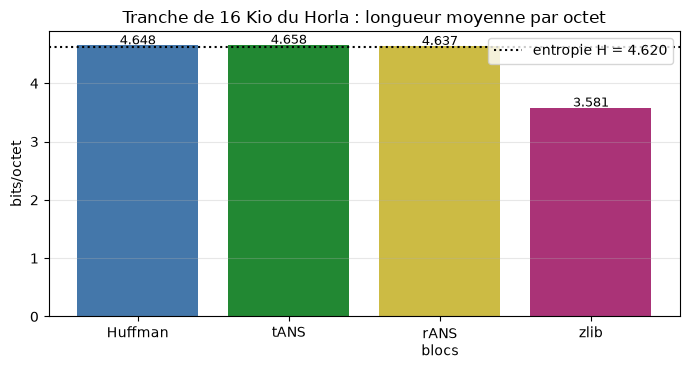

In [12]:
t0 = time.perf_counter()
comp_z = zlib.compress(tranche, 9)
t_enc_z = time.perf_counter() - t0

RESULTATS = {
    "H": H,
    "huffman": 8 * len(comp_huff) / n,
    "tans": bits_tans / n,
    "rans": bits_rans,
    "zlib": 8 * len(comp_z) / n,
}

print(f"{'codeur':<16}{'bits/octet':>12}{'ecart a H':>12}{'encodage':>12}")
print(f"{'entropie H':<16}{H:>12.4f}{'--':>12}{'--':>12}")
for nom, cle, duree in [("Huffman canonique", "huffman", t_enc_huff),
                        ("tANS (L=12)", "tans", t_enc_tans),
                        ("rANS blocs", "rans", t_enc_rans),
                        ("zlib 9", "zlib", t_enc_z)]:
    print(f"{nom:<16}{RESULTATS[cle]:>12.4f}{RESULTATS[cle] - H:>+12.4f}{n / 1024 / 1024 / duree:>9.1f} Mo/s")

fig, ax = plt.subplots(figsize=(7, 3.8))
noms = ["Huffman", "tANS", "rANS\nblocs", "zlib"]
vals = [RESULTATS["huffman"], RESULTATS["tans"], RESULTATS["rans"], RESULTATS["zlib"]]
barres = ax.bar(noms, vals, color=["#4477aa", "#228833", "#ccbb44", "#aa3377"])
ax.axhline(H, color="black", linestyle=":", label=f"entropie H = {H:.3f}")
ax.set_ylabel("bits/octet")
ax.set_title("Tranche de 16 Kio du Horla : longueur moyenne par octet")
ax.legend()
ax.grid(axis="y", alpha=0.3)
for barre, v in zip(barres, vals):
    ax.text(barre.get_x() + barre.get_width() / 2, v + 0.02, f"{v:.3f}",
            ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### Lecture du résultat

Trois lectures :

- **Sur ce corpus plat**, tous les codeurs entropiques sont proches de
  l'entropie ; l'écart de tANS (+0,04) est le prix de la table finie,
  celui de rANS (+0,02) le prix de l'échelle. Le résultat du carnet
  n'est pas ici — il est dans le cas skew de la section 4, où l'écart
  est d'un bit entier.
- **zlib gagne nettement en taux** parce qu'il ne code pas la même
  chose : LZ77 supprime d'abord les répétitions (l'objet du carnet 03),
  et l'entropie qu'il code est celle des *résidus*, plus basse que
  celle des octets bruts.
- **Les débits** mesurent le Python, pas les algorithmes : zlib est
  un à deux ordres de grandeur plus rapide que nos prototypes. La
  version production de tANS (FSE, dans zstd) tient ses tables dans le
  cache L1 et dépasse plusieurs centaines de Mo/s — c'est précisément
  le compromis que Duda cherchait : le taux de l'arithmétique, la
  vitesse de Huffman.

## 6. Exercices

Trois exercices, du diagnostic au réglage. Chaque fonction squelette
retourne `None` tant qu'elle n'est pas complétée : le carnet s'exécute
de bout en bout dans cet état.

In [13]:
# Exercice 1 -- Le point fixe de l'appariement direct
#
# La rotation f//2 de l'appariement intervalle<->slot n'est pas decorative :
# sans elle, l'intervalle de plus basse base du symbole dominant s'apparie
# au slot 0, l'etat N y revient sans cesse et le codeur n'emet plus qu'un
# bit par symbole. Reprenez la construction de TablesTans avec d = 0 et
# mesurez le taux obtenu sur le cas skew.

def bits_sans_rotation(message, frequences, L):
    """TODO etudiant : bits totaux emis par tANS avec l'appariement direct
    (rotation remplacee par l'identite), etat final compris.

    Indice : recopier TablesTans en changeant la seule ligne d = f // 2 en
    d = 0, encoder `message` et retourner flot.taille(). La correction du
    round-trip est inchangee, seul le melange de la chaine d'etats se degrade.
    """
    return None


msg_exo = ["a"] * 990 + ["b"] * 10
ech_exo = construire_echelle({"a": 990, "b": 10}, 10)
res_exo1 = bits_sans_rotation(msg_exo, ech_exo, 10)
if res_exo1 is None:
    print("Exercice a completer : bits_sans_rotation")
else:
    print(f"sans rotation : {res_exo1 / len(msg_exo):.4f} bits/symbole")
    print(f"avec rotation (banc de la section 4) : {bits_skew:.4f} bits/symbole")

Exercice a completer : bits_sans_rotation


In [14]:
# Exercice 2 -- Le surcout d'en-tete en fonction de la taille de bloc
#
# Chaque bloc de rANS evacue son entier d'etat complet dans le flux. Ce
# surcout est amorti sur B symboles : il fond quand B grandit. Mesurez.

def surcout_par_bloc(message, frequences, tailles):
    """TODO etudiant : pour chaque B de `tailles`, encoder `message` avec
    rans_blocs_encoder et rapporter un dict {B: bits/octet}.

    Indice : 8 * len(sortie) / len(message) ; observez l'ecart entre B=64
    et B=4096, puis comparez-le a H de la source.
    """
    return None


res_exo2 = surcout_par_bloc(tranche, freqs, [64, 256, 1024, 4096])
if res_exo2 is None:
    print("Exercice a completer : surcout_par_bloc")
else:
    for B in sorted(res_exo2):
        print(f"B = {B:5d} : {res_exo2[B]:.4f} bits/octet (ecart a H : {res_exo2[B] - H:+.4f})")

Exercice a completer : surcout_par_bloc


In [15]:
# Exercice 3 -- Le compromis de la taille de table L
#
# tANS met les frequences a l'echelle N = 2^L : plus L est grand, plus
# l'echelle est fidele aux probabilites (meilleur taux), plus la table est
# lourde (N entrees). Balayez.

def balayage_L(message, frequences_brutes, liste_L):
    """TODO etudiant : pour chaque L de `liste_L`, mettre les frequences a
    l'echelle avec construire_echelle, construire les tables, encoder
    `message` et rapporter un dict {L: bits/octet}.

    Indice : les frequences brutes de la tranche sont `freqs` ; entre L=8
    et L=14, l'ecart a H doit diminuer de quelques centiemes. Verifiez
    aussi le round-trip sur un L de votre choix.
    """
    return None


res_exo3 = balayage_L(tranche, freqs, [8, 10, 12, 14])
if res_exo3 is None:
    print("Exercice a completer : balayage_L")
else:
    for L in sorted(res_exo3):
        print(f"L = {L:2d} (N = {1 << L:6d}) : {res_exo3[L]:.4f} bits/octet "
              f"(ecart a H : {res_exo3[L] - H:+.4f})")

Exercice a completer : balayage_L


## À retenir

- **ANS brise le plafond du bit entier.** Huffman est borné entre $H$ et
  $H+1$ bits/symbole par ses mots de longueur entière ; sur une source à
  99 % / 1 %, tANS rend 0,09 bit/symbole là où Huffman rend 1,0000.
- **rANS** fait de chaque symbole une multiplication réversible d'un
  entier : l'état croît d'exactement $-\log_2 p_s$ bits, et le
  round-trip se prouve par le retour à l'état initial $M$ — par blocs
  pour borner la mémoire.
- **tANS** fige cette machine dans des tables de $2^L$ états construites
  par pavage dyadique : intervalles issus de $w \in [f, 2f)$, spread des
  slots, appariement tourné. C'est exactement le moteur FSE embarqué
  dans Zstandard.

## Références

- J. Duda, *Asymmetric Numeral Systems: entropy coding combining speed of
  Huffman coding with compression rate of arithmetic coding*,
  [arXiv:1311.2540](https://arxiv.org/abs/1311.2540) — l'article qui
  systématise la famille, dans la lignée de Szczepanski et al. (2009).
- F. Giesen, *Interleaved entropy coders*,
  [arXiv:1402.3392](https://arxiv.org/abs/1402.3392) — la variante rANS
  entrelacée (ryg_rans), renormalisée par symbole, qui équipe LZFSE.
- Y. Collet, la bibliothèque **FSE** et le format
  [Zstandard](https://github.com/facebook/zstd) — le déploiement
  industriel de tANS, sur le même principe de tables que la section 4.

Le carnet suivant (*Compression-04b, codecs SOTA*, pli 6 de l'EPIC)
ouvrira les codecs modernes avec ces tables en main : comment la
famille ANS y est déployée aux côtés des modèles LZ du carnet 03.